# 011-2. 승차인원 Ridge 외부검증 및 격자별 오차 지도

**비중을 제외한 5변수**: 개통 전 승차인원, GTX역 보행시간, 경쟁 목적지 비율, 평균 버스 통행시간, log(1+건축물 연면적).

- 분석 표본: 기존 GTX-A 126개 격자. 정답: 실제 2025년 11월 6일 승차인원. 예측 출력: 개통 후 승차인원(명).
- 현재 채택한 최종 모형: **개통 전·후 승차인원은 원 단위, 보행시간은 log(1+분)**. OLS와 보행 변환을 통일하여 현재 채택한 모형 사양이다. GTX-C 적용의 타당성이 확정된 것은 아니다.
- 보행시간과 연면적은 log(1+x)로 고정한다. 입력 승차인원/정답 승차인원의 로그 여부를 분리한 4개 설정과 개통 전 승차인원 제외 모형을 비교한다.
- 외부 LOSO: 2개 역에서 학습하고 남은 1개 역을 예측. 내부 LOSO에서 결측치 대체·표준화·규제 alpha를 선택한다. 선택 지표는 **원 단위 MAE의 역별 평균**이다.
- 각 후보의 규제 선택을 검증에 포함하지만, 이 표를 보고 후보를 고른 성능은 탐색적이다. 반복 탐색과 3개 역이라는 한계가 남는다.
- 지도는 학습자료를 다시 맞춘 값이 아니라 **126개 외부검증 OOF 예측값**만 사용한다. 결과 CSV·HTML·모델 파일을 자동 저장하지 않는다.


## 현재 채택한 최종 모형: 원 단위 승차인원 Ridge 회귀 (5변수)

**모형명: 비중 제외 · 보행시간/연면적 로그 · 원 단위 승차인원 Ridge 회귀**

여기서 최종은 **현재 연구에서 채택한 모형 사양**을 뜻한다. 모든 후보보다 우수하다는 판정이나 GTX-C 성능 입증을 의미하지 않는다.

| 구분 | 현재 채택 내용 |
|---|---|
| 분석 단위 | GTX-A 공급구조 유지 250m 격자 126개 |
| 입력 1 | 2024년 개통 전 승차인원(명), 로그 없음 |
| 입력 2 | log(1 + GTX역 보행시간[분]) |
| 입력 3 | GTX 경쟁 목적지 비율(%) |
| 입력 4 | 평균 버스 통행시간(분) |
| 입력 5 | log(1 + 2024년 건축물 연면적[천㎡]) |
| 제외 변수 | 개통 전 수요 비중 |
| 정답값 y | 실제 2025년 11월 6일 승차인원(명), 로그 없음 |
| 예측값 | 격자별 개통 후 예상 승차인원(명) |
| 학습 방법 | L2 규제를 적용한 Ridge 회귀 |
| 전처리 | 학습자료의 중앙값으로 결측치 대체 후 학습자료의 평균·표준편차로 표준화 |
| 검증 | 외부 Leave-One-Station-Out + 학습역 내부 LOSO로 alpha 선택 |
| 최종 출력 처리 | 음수 예측은 0으로 처리; 지표 산출 전 반올림하지 않음 |

### 모형식

입력 벡터를 다음과 같이 둔다.

\[
\mathbf{x}_i=\left(
B_{i,2024},\;\log(1+T_{i,walk}),\;C_i,\;T_{i,bus},\;\log(1+F_i)
\right).
\]

각 입력을 **해당 학습자료의 통계량**으로 표준화한 값을 \(z_{ij}\)라 하면,

\[
\widehat B_{i,2025}=\max\left(0,\;\widehat\beta_0+\sum_{j=1}^{5}\widehat\beta_j z_{ij}\right).
\]

학습은 다음 목적함수를 최소화한다(절편은 규제하지 않음).

\[
\min_{\beta_0,\boldsymbol\beta}
\sum_{i\in\mathrm{train}}\left(B_{i,2025}-\beta_0-\sum_{j=1}^{5}\beta_jz_{ij}\right)^2
+\alpha\sum_{j=1}^{5}\beta_j^2.
\]

\(C_i\): 경쟁 목적지 비율, \(T_{i,bus}\): 평균 버스 통행시간, \(F_i\): 건축물 연면적(천㎡).
보행시간과 연면적에는 OLS와 동일한 `log(1+x)` 변환을 적용한다. 이 선택이 예측력 우위를 자동으로 보장하지는 않는다.

### 현재 외부검증 결과

| 검증역 | 격자 수 | 선택 alpha | MAE(명) | RMSE(명) | R² |
|---|---:|---:|---:|---:|---:|
| 운정중앙 | 63 | 10 | 13.155 | 20.289 | 0.8530 |
| 킨텍스 | 26 | 10 | 21.235 | 35.322 | 0.9381 |
| 대곡 | 37 | 0.1 | 8.428 | 19.243 | 0.8487 |
| 전체 OOF | 126 | 역별 선택 | **13.434** | **23.917** | **0.9200** |

전체 OOF는 각 격자를 학습에서 제외한 예측을 126개 모아 계산한 값이다. R² 0.9200은 ‘정확도 92%’가 아니다. 원 단위 Ridge의 음수 예측은 운정중앙 19개, 대곡 3개(총 22개)에서 0으로 처리되었으며 표의 성능은 이 처리 후 수치이다.

**판단:** 총량비례 기준모형(MAE 11.429명)보다 MAE가 높다. 따라서 현재 모형은 연구 목적과 변수 해석을 고려해 채택한 사양이며, 기준모형 대비 예측 우위가 확인된 것은 아니다. 3개 역·하루 합성자료·반복 탐색의 한계를 함께 보고한다.

**저장 및 적용 상태:** 이 노트북은 외부검증 모형을 실행하고 결과를 시각화한다. 전체 126개로 재학습한 단일 배포용 모델 파일은 아직 생성하지 않았다. GTX-C 적용 시에는 A 전체 자료 안에서 alpha를 선택해 전처리와 모델을 다시 적합하고, C의 변수 정의·분포를 확인해야 한다. 위 표의 역별 모형을 하나의 공통 계수식으로 해석하지 않는다.


In [1]:
# 프로젝트 루트(UROP) 자동 탐색 — 절대경로 없이 어느 컴퓨터에서도 동작
import sys
from pathlib import Path
UROP_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'config.py').is_file() and (p / 'code').is_dir())
for _d in [UROP_ROOT, *sorted(d for d in (UROP_ROOT / 'code').rglob('*') if d.is_dir() and d.name != '__pycache__')]:
    if str(_d) not in sys.path:
        sys.path.append(str(_d))

from pathlib import Path
import sys, os, getpass
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display

candidates = [*sorted(d for d in (UROP_ROOT / 'code').rglob('*') if d.is_dir()), Path.cwd(), Path.cwd()/'analysis', Path.cwd()/'gtx_a_bus_analysis'/'analysis',
              Path.cwd()/'github_2026-UROP'/'gtx_a_bus_analysis'/'analysis']
ANALYSIS = next((p for p in candidates if (p/'ridge_count_validation.py').exists()), None)
if ANALYSIS is None:
    raise FileNotFoundError('analysis 폴더에서 실행하세요.')
if str(ANALYSIS) not in sys.path: sys.path.insert(0, str(ANALYSIS))
import ridge_count_validation as experiment

available = {f.name for f in font_manager.fontManager.ttflist}
font = next((f for f in ['AppleGothic', 'Apple SD Gothic Neo', 'NanumGothic', 'Malgun Gothic', 'Noto Sans CJK KR'] if f in available), None)
if font: plt.rcParams['font.family'] = font
else: print('한글 폰트가 없습니다. AppleGothic 또는 NanumGothic을 설치한 뒤 커널을 다시 실행하세요.')
plt.rcParams.update({'axes.unicode_minus': False, 'figure.dpi': 120, 'font.size': 11})
pd.set_option('display.max_columns', 25)
data = experiment.load_data()
print('표본:', len(data), '| 한글 폰트:', font)
display(data.groupby('nearest_station').agg(격자수=('셀 ID','size'), 개통전승차=('board_2024_all','sum'), 개통후승차=('board_2025_all','sum')))


표본: 126 | 한글 폰트: AppleGothic
                 격자수   개통전승차   개통후승차
nearest_station                     
대곡                37  2622.0  1016.0
운정중앙              63  6491.0  1911.0
킨텍스               26  8781.0  2658.0


## 1. 왜 로그를 썼는가? 이번에는 무엇을 바꾸는가?

승차인원의 큰 값과 긴 꼬리의 영향을 줄이고 비례적인 변화를 표현하려는 목적이었다. **로그는 필수 조건이 아니다.**

- 입력(2024년)에 로그: 승차규모와 결과의 관계를 비선형으로 표현한다.
- 정답(2025년)에 로그: 학습 오차를 로그 척도에서 계산하므로 큰 격자의 절대오차 비중이 줄어든다. 역변환값이 원 단위 평균의 불편추정값인 것은 아니다(별도 편향 보정 없음).
- 보행시간에 로그: 가까운 구간에서의 시간 차이를 상대적으로 더 크게 반영한다. OLS에서 사용했다고 예측모형에서도 반드시 좋아지는 것은 아니다.
- 원 단위 승차모형은 큰 승차규모의 오차에 더 민감하다. 양쪽 모두 실제 승차인원 단위의 MAE/RMSE로 검증한다.
- 모든 모형은 음수 승차인원 예측을 0으로 처리한다. 처리 개수도 역별 표에 표시한다. 예측값은 평가 전에 반올림하지 않는다.


In [2]:
feature_table = pd.DataFrame([
    ['개통 전 승차인원', 'board_2024_all', '명', '원 단위'],
    ['GTX역 보행시간', 'log1p_walk_min', 'log(1+분)', '로그'],
    ['GTX 경쟁 목적지 비율', 'competing_share', '%', '원 단위'],
    ['평균 버스 통행시간', 'bus_time_mean', '분', '원 단위'],
    ['건축물 연면적', 'log1p_floor_area', 'log(1+천㎡)', '로그'],
], columns=['입력 피처', '코드 변수명', '척도', '기본 표시 모형'])
display(feature_table)
display(pd.DataFrame([{'모형': name, '입력승차 로그': x['xlog'], '정답승차 로그': x['ylog'], '보행시간 로그': x['wlog']}
                     for name, x in experiment.MODELS.items()]))


,입력 피처,코드 변수명,척도,기본 표시 모형
0,개통 전 승차인원,board_2024_all,명,원 단위
1,GTX역 보행시간,log1p_walk_min,log(1+분),로그
2,GTX 경쟁 목적지 비율,competing_share,%,원 단위
3,평균 버스 통행시간,bus_time_mean,분,원 단위
4,건축물 연면적,log1p_floor_area,log(1+천㎡),로그


,모형,입력승차 로그,정답승차 로그,보행시간 로그
0,승차원단위_보행로그,False,False,True
1,승차정답로그_보행로그,False,True,True
2,승차입력로그_보행로그,True,False,True
3,승차양쪽로그_보행로그,True,True,True
4,개통전승차제외_보행로그,False,False,True


In [3]:
overall, fold_metrics, all_oof = experiment.evaluate(data)
print('전체 OOF 지표: 역별 지표 평균과 다릅니다.')
display(overall.round(3))
print('역별 지표 / 학습역 내부에서 선택한 alpha / 음수 예측 처리 수')
display(fold_metrics.round(3))


전체 OOF 지표: 역별 지표 평균과 다릅니다.
역별 지표 / 학습역 내부에서 선택한 alpha / 음수 예측 처리 수


,모형,MAE(명),RMSE(명),R²,평균오차(예측-실제),WAPE(%)
0,승차원단위_보행로그,13.434,23.917,0.920,-0.982,30.308
1,승차정답로그_보행로그,41.080,205.244,-4.892,2.762,92.677
2,승차입력로그_보행로그,35.852,69.208,0.330,4.282,80.884
3,승차양쪽로그_보행로그,15.729,42.751,0.744,-9.015,35.484
4,개통전승차제외_보행로그,50.004,88.100,-0.086,-0.904,112.812
5,총량비례 기준,11.429,22.511,0.929,0.882,25.784


,모형,검증역,n,alpha,내부MAE,음수예측_0처리수,MAE(명),RMSE(명),R²,평균오차(예측-실제),WAPE(%)
0,승차원단위_보행로그,운정중앙,63,10.000,34.386,19,13.155,20.289,0.853,1.599,43.369
1,승차정답로그_보행로그,운정중앙,63,100.000,50.624,0,20.578,46.651,0.223,-13.300,67.841
2,승차입력로그_보행로그,운정중앙,63,0.001,52.106,25,29.357,45.088,0.274,18.285,96.782
3,승차양쪽로그_보행로그,운정중앙,63,0.001,24.150,1,8.801,16.603,0.902,1.473,29.013
4,개통전승차제외_보행로그,운정중앙,63,0.001,77.986,27,34.632,57.242,-0.170,5.840,114.171
5,총량비례 기준,운정중앙,63,NaN,NaN,0,8.705,14.568,0.924,2.863,28.697
6,승차원단위_보행로그,킨텍스,26,10.000,10.297,0,21.235,35.322,0.938,-2.594,20.771
7,승차정답로그_보행로그,킨텍스,26,100.000,19.280,0,121.601,442.672,-8.726,56.850,118.948
8,승차입력로그_보행로그,킨텍스,26,10.000,18.766,0,66.185,127.726,0.190,-45.396,64.740
9,승차양쪽로그_보행로그,킨텍스,26,0.001,9.859,0,41.622,85.229,0.639,-38.192,40.713


## 2. 보행시간 로그를 고정한 승차인원 변환 비교

핵심 비교는 **승차 양쪽 원 단위**와 **승차 양쪽 로그**이다. 모든 모형에서 보행시간과 연면적은 로그로 고정한다. 개통 전 승차인원 제외 모형은 4변수를 사용한다.
총량비례 기준은 학습역의 개통 후 합계 ÷ 개통 전 합계를 검증격자의 개통 전 승차인원에 곱한다. 검증역의 실제 개통 후 합계는 사용하지 않는다.

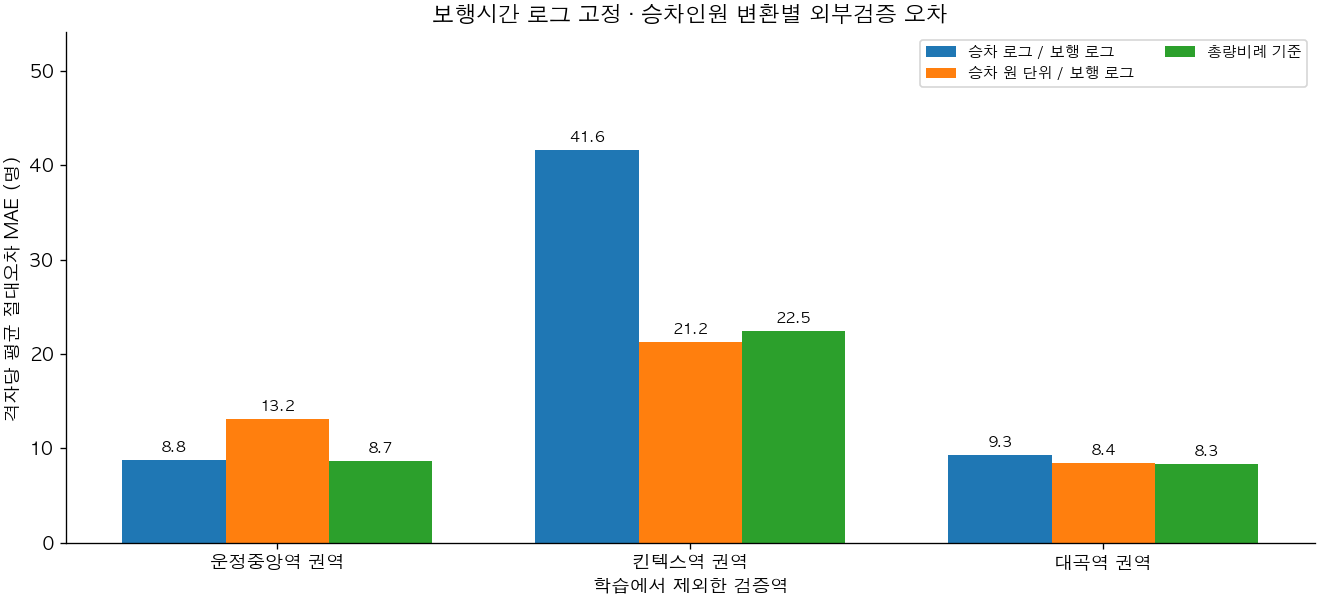

In [4]:
comparison_names = ['승차양쪽로그_보행로그', '승차원단위_보행로그', '총량비례 기준']
comparison_labels = ['승차 로그 / 보행 로그', '승차 원 단위 / 보행 로그', '총량비례 기준']
pivot = fold_metrics.pivot(index='검증역', columns='모형', values='MAE(명)').reindex(experiment.STATIONS)
fig, ax = plt.subplots(figsize=(11, 5), layout='constrained')
x = np.arange(3); width = .25
for i, (name, label) in enumerate(zip(comparison_names, comparison_labels)):
    bars = ax.bar(x+(i-1)*width, pivot[name], width, label=label)
    ax.bar_label(bars, fmt='%.1f', padding=3, fontsize=9)
ax.set_xticks(x, [s+'역 권역' for s in experiment.STATIONS])
ax.set_xlabel('학습에서 제외한 검증역'); ax.set_ylabel('격자당 평균 절대오차 MAE (명)')
ax.set_title('보행시간 로그 고정 · 승차인원 변환별 외부검증 오차')
ax.set_ylim(0, pivot[comparison_names].max().max()*1.30)
ax.legend(fontsize=9, ncol=2); ax.spines[['top','right']].set_visible(False)
plt.show()


## 3. 개통 전 승차인원의 예측 기여

개통 전 승차인원은 현재 격자의 기존 수요 규모를 나타낸다. 이 변수를 제외했을 때 오차가 얼마나 달라지는지 **동일한 외부 역별 검증**으로 비교한다. 이 비교는 해당 변수의 예측 기여를 보여주며 GTX 개통의 인과효과나 변수별 통계적 유의성을 뜻하지 않는다.

각 막대의 MAE는 126개 격자 전체 OOF 값이다. 단순 기준모형은 학습역의 총량 감소 비율만 개통 전 승차인원에 적용한다.

개통 전 승차인원 제외 모형의 권역별 결과


,MAE(명),RMSE(명),R²
모형,,,
총량비례 기준,11.43,22.51,0.93
승차원단위_보행로그,13.43,23.92,0.92
개통전승차제외_보행로그,50.00,88.10,-0.09


,검증역,n,MAE(명),RMSE(명),R²
4,운정중앙,63,34.63,57.24,-0.17
10,킨텍스,26,83.41,155.33,-0.20
16,대곡,37,52.71,62.44,-0.59


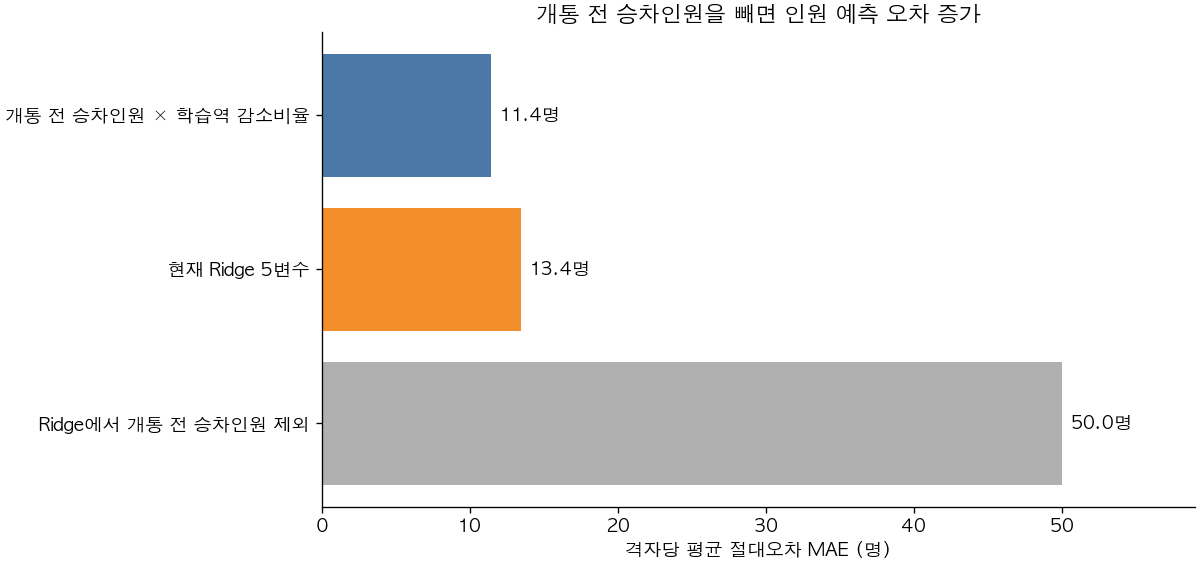

In [5]:
contribution_names = ['총량비례 기준', experiment.PRIMARY, '개통전승차제외_보행로그']
contribution_labels = ['개통 전 승차인원 × 학습역 감소비율', '현재 Ridge 5변수', 'Ridge에서 개통 전 승차인원 제외']
contribution = overall.set_index('모형').loc[contribution_names]
display(contribution[['MAE(명)','RMSE(명)','R²']].rename_axis('모형').round(2))
print('개통 전 승차인원 제외 모형의 권역별 결과')
display(fold_metrics[fold_metrics['모형']=='개통전승차제외_보행로그'][['검증역','n','MAE(명)','RMSE(명)','R²']].round(2))
fig, ax = plt.subplots(figsize=(10,4.7), layout='constrained')
bars = ax.barh(contribution_labels, contribution['MAE(명)'], color=['#4C78A8','#F28E2B','#B0B0B0'])
ax.bar_label(bars, fmt='%.1f명', padding=5)
ax.invert_yaxis(); ax.set_xlim(0, contribution['MAE(명)'].max()*1.18)
ax.set(xlabel='격자당 평균 절대오차 MAE (명)', title='개통 전 승차인원을 빼면 인원 예측 오차 증가')
ax.spines[['top','right']].set_visible(False)
plt.show()


## 4. 지도와 상세 그래프에 사용할 모형

기본값은 사용자가 요청한 **승차 원 단위 + 보행 로그**이다. 아래 이름을 바꾸면 다른 설정의 동일한 OOF 결과를 확인할 수 있다. 표시 모형 변경은 성능을 확인하는 탐색이며 새로운 검증 자료가 생기는 것은 아니다.


In [6]:
MODEL_TO_MAP = experiment.PRIMARY  # '승차원단위_보행로그'
# 다른 예: '승차양쪽로그_보행로그' (보행시간은 항상 로그)
selected = all_oof[all_oof['모형']==MODEL_TO_MAP].copy()
assert len(selected)==126 and selected['셀 ID'].nunique()==126
print('표시 모형:', MODEL_TO_MAP)
display(overall[overall.모형==MODEL_TO_MAP].round(3))
display(fold_metrics[fold_metrics.모형==MODEL_TO_MAP].round(3))


표시 모형: 승차원단위_보행로그


,모형,MAE(명),RMSE(명),R²,평균오차(예측-실제),WAPE(%)
0,승차원단위_보행로그,13.434,23.917,0.92,-0.982,30.308


,모형,검증역,n,alpha,내부MAE,음수예측_0처리수,MAE(명),RMSE(명),R²,평균오차(예측-실제),WAPE(%)
0,승차원단위_보행로그,운정중앙,63,10.0,34.386,19,13.155,20.289,0.853,1.599,43.369
6,승차원단위_보행로그,킨텍스,26,10.0,10.297,0,21.235,35.322,0.938,-2.594,20.771
12,승차원단위_보행로그,대곡,37,0.1,20.195,3,8.428,19.243,0.849,-4.243,30.692


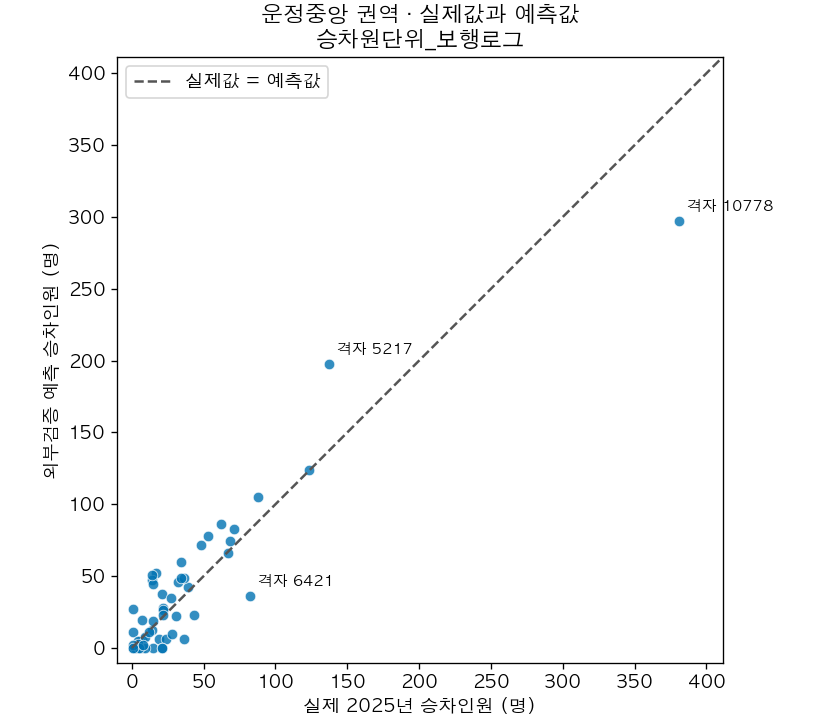

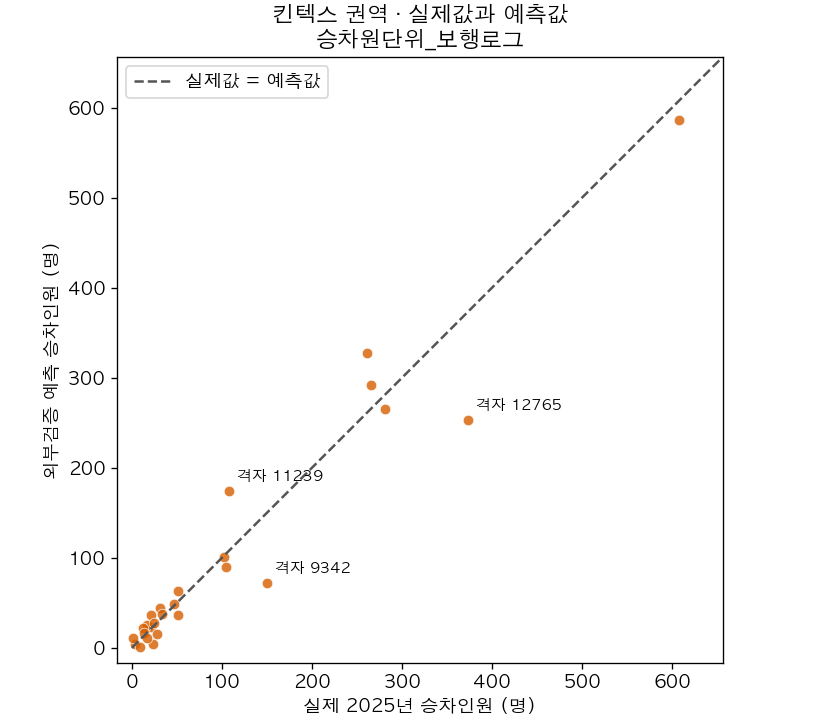

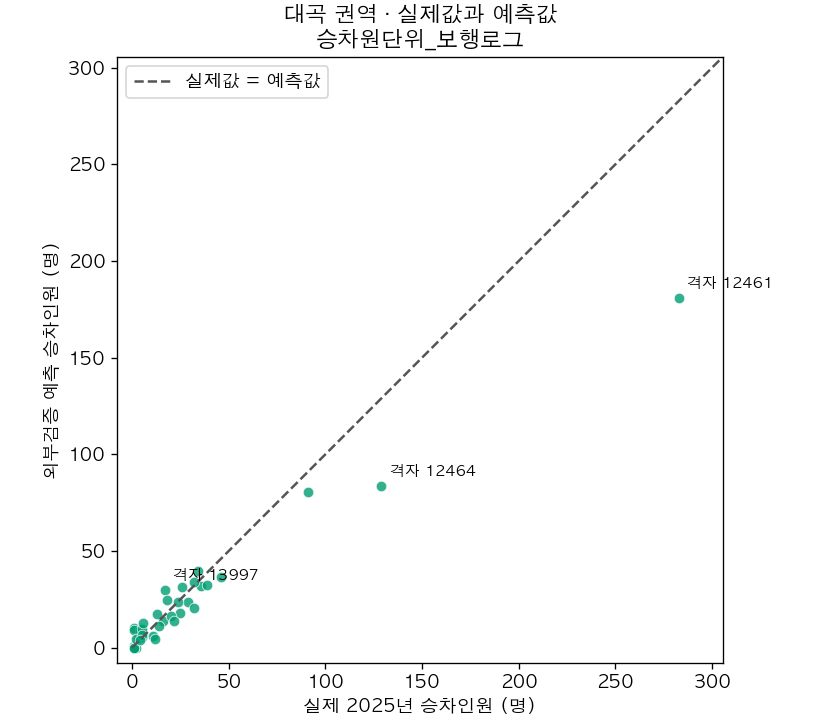

In [7]:
station_colors = {'운정중앙':'#0072B2', '킨텍스':'#D55E00', '대곡':'#009E73'}
for station in experiment.STATIONS:
    part = selected[selected.nearest_station==station]
    fig, ax = plt.subplots(figsize=(7,6), layout='constrained')
    ax.scatter(part.board_2025_all, part['예측승차인원'], s=40, alpha=.8,
               color=station_colors[station], edgecolor='white', linewidth=.5)
    upper = max(part.board_2025_all.max(), part['예측승차인원'].max(), 1)*1.08
    ax.plot([0,upper],[0,upper], '--', color='#555555', label='실제값 = 예측값')
    for _, row in part.nlargest(3, '절대오차').iterrows():
        ax.annotate(f"격자 {int(row['셀 ID'])}", (row.board_2025_all,row['예측승차인원']),
                    xytext=(5,6), textcoords='offset points', fontsize=9)
    ax.set(xlim=(-upper*.025,upper), ylim=(-upper*.025,upper),
           xlabel='실제 2025년 승차인원 (명)', ylabel='외부검증 예측 승차인원 (명)',
           title=f'{station} 권역 · 실제값과 예측값\n{MODEL_TO_MAP}')
    ax.set_aspect('equal', adjustable='box'); ax.legend(loc='upper left'); plt.show()


## 5. 오차가 특정 규모·권역에 집중되는가?

오차 = **예측 − 실제**. 양수는 과대예측, 음수는 과소예측이다. 산점도의 세로축은 모델이 잘못 예측한 인원 수이다.


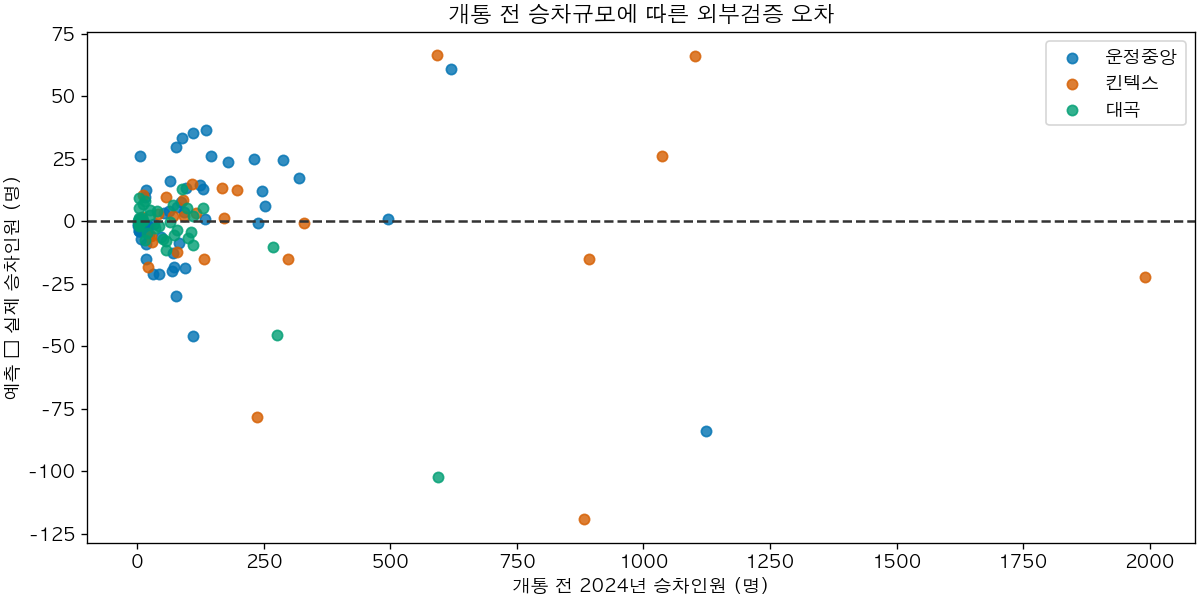

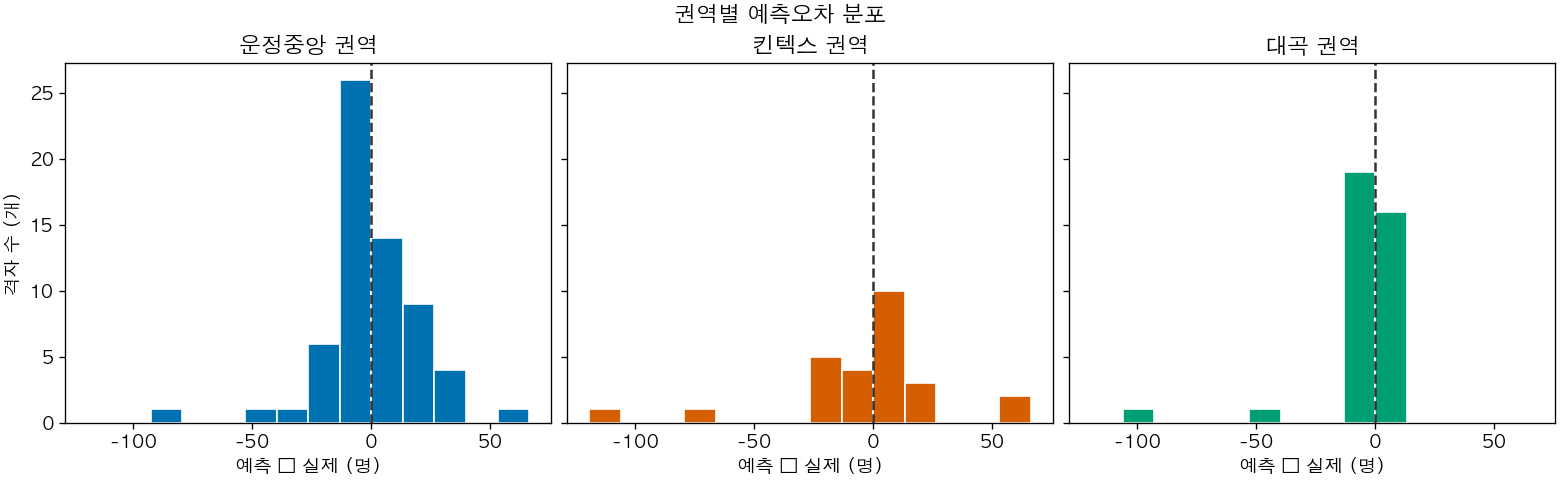

,격자수,실제평균,예측평균,MAE_명,평균오차_명
개통전승차 규모,,,,,
20명 미만,41,4.34,4.74,4.27,0.40
20~100명 미만,45,19.80,18.14,9.64,-1.66
100~300명 미만,28,53.75,55.21,17.94,1.46
300명 이상,12,250.92,242.09,48.45,-8.82


In [8]:
fig, ax = plt.subplots(figsize=(10,5), layout='constrained')
for station in experiment.STATIONS:
    part = selected[selected.nearest_station==station]
    ax.scatter(part.board_2024_all, part['오차'], label=station, alpha=.8, s=38, color=station_colors[station])
ax.axhline(0, color='#333333', linestyle='--')
ax.set(xlabel='개통 전 2024년 승차인원 (명)', ylabel='예측 − 실제 승차인원 (명)',
       title='개통 전 승차규모에 따른 외부검증 오차')
ax.legend(); plt.show()

fig, axes = plt.subplots(1,3,figsize=(13,4),layout='constrained',sharex=True,sharey=True)
bins = np.linspace(min(selected['오차'].min(),-1), max(selected['오차'].max(),1), 15)
for ax, station in zip(axes, experiment.STATIONS):
    part = selected[selected.nearest_station==station]
    ax.hist(part['오차'], bins=bins, color=station_colors[station], edgecolor='white')
    ax.axvline(0,color='#333333',linestyle='--')
    ax.set_title(station+' 권역'); ax.set_xlabel('예측 − 실제 (명)')
axes[0].set_ylabel('격자 수 (개)'); fig.suptitle('권역별 예측오차 분포'); plt.show()

size_check = selected.copy()
size_check['개통전승차 규모'] = pd.cut(size_check.board_2024_all, [-np.inf,20,100,300,np.inf],
                                     right=False,labels=['20명 미만','20~100명 미만','100~300명 미만','300명 이상'])
display(size_check.groupby('개통전승차 규모', observed=True).agg(
    격자수=('셀 ID','size'), 실제평균=('board_2025_all','mean'), 예측평균=('예측승차인원','mean'),
    MAE_명=('절대오차','mean'), 평균오차_명=('오차','mean')).round(2))


## 6. 실제 격자 경계와 좌표 연결

011·011-1과 같은 원본 경계, 공간 필터, 중복 제거, 셀 ID 생성 순서를 사용한다. 좌표는 격자 중심점의 위도·경도이다.
**오차가 작은 격자**는 절대오차 기준이다. 승차인원이 적은 격자에서는 상대적으로 작은 오차가 쉽게 나타날 수 있으므로 실제·예측 규모를 함께 본다.


In [9]:
geometry_data = experiment.attach_geometry(data)
plot = geometry_data.merge(selected[['셀 ID','예측승차인원','오차','절대오차']], on='셀 ID', validate='one_to_one')
plot = experiment.tag_errors(plot)
assert len(plot)==126
columns = ['셀 ID','board_2024_all','board_2025_all','예측승차인원','오차','절대오차','위도','경도']
rename = {'board_2024_all':'2024년 승차(명)','board_2025_all':'실제 2025년(명)','예측승차인원':'예측 2025년(명)'}
for station in experiment.STATIONS:
    part = plot[plot.nearest_station==station]
    print(f'[{station}] 절대오차 작은 3개 (녹색 G1~G3)')
    good = part.sort_values('작은오차순위').head(3)
    display(good[['작은오차순위',*columns]].rename(columns=rename).round({'예측 2025년(명)':2,'오차':2,'절대오차':2,'위도':6,'경도':6}))
    print(f'[{station}] 절대오차 큰 3개 (노란색 W1~W3)')
    bad = part.sort_values('큰오차순위').head(3)
    display(bad[['큰오차순위',*columns]].rename(columns=rename).round({'예측 2025년(명)':2,'오차':2,'절대오차':2,'위도':6,'경도':6}))


[운정중앙] 절대오차 작은 3개 (녹색 G1~G3)
[운정중앙] 절대오차 큰 3개 (노란색 W1~W3)
[킨텍스] 절대오차 작은 3개 (녹색 G1~G3)
[킨텍스] 절대오차 큰 3개 (노란색 W1~W3)
[대곡] 절대오차 작은 3개 (녹색 G1~G3)
[대곡] 절대오차 큰 3개 (노란색 W1~W3)


,작은오차순위,셀 ID,2024년 승차(명),실제 2025년(명),예측 2025년(명),오차,절대오차,위도,경도
63,1,9146,10.0,4.0,4.58,0.58,0.58,37.743989,126.729589
109,2,13315,495.0,123.0,123.77,0.77,0.77,37.723522,126.701433
40,3,5754,239.0,67.0,66.18,-0.82,0.82,37.732923,126.760912


,큰오차순위,셀 ID,2024년 승차(명),실제 2025년(명),예측 2025년(명),오차,절대오차,위도,경도
81,1,10778,1123.0,381.0,296.92,-84.08,84.08,37.710302,126.746956
37,2,5217,619.0,137.0,197.83,60.83,60.83,37.716988,126.735542
43,3,6421,110.0,82.0,35.92,-46.08,46.08,37.714413,126.687349


,작은오차순위,셀 ID,2024년 승차(명),실제 2025년(명),예측 2025년(명),오차,절대오차,위도,경도
45,1,6874,330.0,102.0,101.25,-0.75,0.75,37.681206,126.778437
93,2,12253,172.0,47.0,48.24,1.24,1.24,37.674429,126.775668
17,3,2268,9.0,3.0,4.72,1.72,1.72,37.681258,126.786942


,큰오차순위,셀 ID,2024년 승차(명),실제 2025년(명),예측 2025년(명),오차,절대오차,위도,경도
101,1,12765,882.0,373.0,253.69,-119.31,119.31,37.662986,126.747434
65,2,9342,236.0,150.0,71.89,-78.11,78.11,37.681083,126.758592
85,3,11239,593.0,108.0,174.50,66.50,66.50,37.672052,126.755847


,작은오차순위,셀 ID,2024년 승차(명),실제 2025년(명),예측 2025년(명),오차,절대오차,위도,경도
8,1,1235,6.0,1.0,0.98,-0.02,0.02,37.654485,126.832545
52,2,7608,11.0,6.0,6.06,0.06,0.06,37.715432,126.851854
115,3,14004,1.0,4.0,4.26,0.26,0.26,37.692915,126.854886


,큰오차순위,셀 ID,2024년 승차(명),실제 2025년(명),예측 2025년(명),오차,절대오차,위도,경도
95,1,12461,595.0,283.0,180.72,-102.28,102.28,37.618481,126.841365
96,2,12464,277.0,129.0,83.68,-45.32,45.32,37.618513,126.847031
114,3,13997,89.0,17.0,29.87,12.87,12.87,37.622956,126.835660


## 7. 권역별 카카오 지도 — 실제 / 예측 / 오차

권역마다 실제·예측 지도 2장과 큰 오차지도 1장을 출력한다. 실제·예측은 공통 승차규모 범례, 오차는 공통 인원 기준 범례를 사용한다.

- 파란 오차 격자: 과소예측 / 붉은 오차 격자: 과대예측 / 회색: 오차 ±5명 이내(표시용 구간으로 정확성의 합격 기준 아님).
- **녹색 테두리 G1~G3**: 해당 권역에서 절대오차가 작은 3개.
- **노란 테두리 W1~W3**: 해당 권역에서 절대오차가 큰 3개.
- 클릭: 실제값·예측값·오차·보행시간·좌표. 새 창 링크로 지도를 크게 볼 수 있다.
- 기존 011 지도 서버를 종료하지 않는다. 8765 사용 중이면 8766~8768 중 비어 있는 포트를 사용한다. 출력된 `http://localhost:포트`를 카카오 JavaScript 키의 사이트 도메인에 등록해야 한다.
- **JavaScript 키**는 실행 시 입력한다(REST API 키가 아님). 노트북 소스나 결과 파일에 키를 저장하지 않는다.


In [ ]:
import importlib
import kakao_ridge_error_overlay
# 수정된 서버 코드를 반영한다. 이 011-2 모듈의 서버만 종료하고 다시 시작한다.
kakao_ridge_error_overlay.stop()
kakao_ridge_error_overlay = importlib.reload(kakao_ridge_error_overlay)
kakao_js_key = os.environ.get('KAKAO_JAVASCRIPT_KEY','').strip() or getpass.getpass('카카오 JavaScript 키: ').strip()
try:
    kakao_ridge_error_overlay.show_maps(plot, MODEL_TO_MAP, kakao_js_key)
finally:
    del kakao_js_key


## 해석의 범위

이 지도는 GTX-A에서 어느 격자의 **개통 후 승차규모**를 잘 예측했는지 보여준다. GTX 영향의 인과효과, 비중 확대 분류, GTX-C 예측 결과를 나타내는 지도가 아니다. 오차가 큰 격자는 실제 수요·정류장·환승거점 등을 점검할 사례이며 오류 확인 없이 표본에서 제거하지 않는다. 현장 공간 확인은 원인을 확정하는 증거가 아닌 추가 해석 자료이다.
